# 06 · Smoothing

`s.smooth(method, **settings)`. Smoothing more removes more noise but makes narrow bands lower and wider; the settings control that. Windows are in points (1.19 cm⁻¹ each here).

| method | main setting | note |
|---|---|---|
| `savgol` (default) | `window` 15, `order` 4 | keeps band shape best; the standard |
| `whittaker` | `lam` 3 | no window; good at the ends |
| `spline` | `lam` None = automatic | chooses the amount itself |
| `gaussian` | `sigma` 1 | |
| `moving` | `window` 5 | lowers bands most |
| `median` | `window` 5 | flattens band tops |
| `fourier` | `cutoff` 0.25 | removes high frequencies |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import spectrum_toolkit as stk
from spectrum_toolkit.smooth import METHODS, DEFAULTS

cv = stk.load('../data/CV10-4M.xlsx', verbose=False).despike(verbose=False).baseline()
wt = stk.load('../data/wt_raw.mat', verbose=False).trim(441, 1818)
s = cv[0]

## 1. All methods, zoomed on two bands (CV) and on a noisy map spectrum

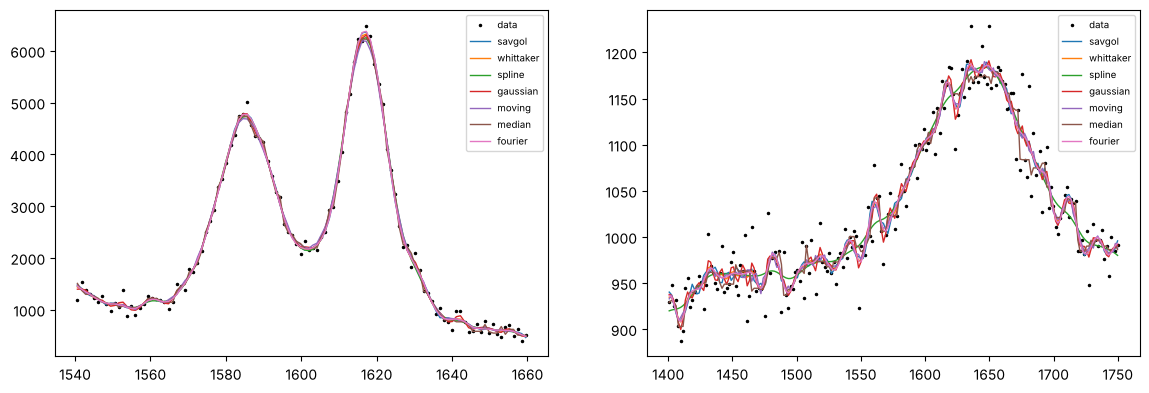

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, sp, (lo, hi) in [(ax[0], s, (1540, 1660)), (ax[1], wt[100], (1400, 1750))]:
    m = (sp.x > lo) & (sp.x < hi)
    a.plot(sp.x[m], sp.y[m], 'k.', ms=3, label='data')
    for meth in METHODS:
        a.plot(sp.x[m], sp.smooth(meth).y[m], lw=1, label=meth)
    a.legend(fontsize=7)
plt.show()

## 2. Play with the settings

In [3]:
from ipywidgets import interact, Dropdown, IntSlider, FloatLogSlider, FloatSlider

def show(spectrum='CV 1', method='savgol', window=15, order=4, lam=3.0, sigma=1.0, cutoff=0.25, auto_spline=True):
    sp = s if spectrum == 'CV 1' else wt[100]
    given = dict(window=window, order=order, lam=None if (method == 'spline' and auto_spline) else lam, sigma=sigma, cutoff=cutoff)
    settings = {k: v for k, v in given.items() if k in DEFAULTS[method]}
    try:
        z = sp.smooth(method, **settings)
    except ValueError as e:
        print(e); return
    fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    ax[0].plot(sp.x, sp.y, color='0.6', lw=0.7); ax[0].plot(z.x, z.y, 'b', lw=1); ax[0].set_title(f'{method} {settings}')
    ax[1].plot(sp.x, sp.y - z.y, 'k', lw=0.6); ax[1].set_title('removed (should look like pure noise)')
    plt.show()

interact(show, spectrum=Dropdown(options=['CV 1', 'map 100']), method=Dropdown(options=METHODS),
         window=IntSlider(value=15, min=3, max=51, step=2), order=IntSlider(value=4, min=1, max=8),
         lam=FloatLogSlider(value=3, base=10, min=-1, max=4), sigma=FloatSlider(value=1, min=0.5, max=6, step=0.5),
         cutoff=FloatSlider(value=0.25, min=0.02, max=1, step=0.01));

interactive(children=(Dropdown(description='spectrum', options=('CV 1', 'map 100'), value='CV 1'), Dropdown(de…

The lower plot shows what was removed. If band shapes appear in it, the smoothing is too strong.

## 3. A whole collection

In [4]:
cv_smooth = cv.smooth()
cv_smooth.history

({'step': 'despike',
  'method': 'single',
  'threshold': 8.0,
  'width': 3,
  'sharpness': 1.0,
  'grow': 3.0,
  'passes': 2,
  'spikes': {'Spectrum 4': [{'x_from': 1634.62695,
     'x_to': 1636.79688,
     'points': 3,
     'change': -2725.3405570183495},
    {'x_from': 1696.18359,
     'x_to': 1701.55664,
     'points': 6,
     'change': -9027.529511807266}],
   'Spectrum 11': [{'x_from': 313.29883,
     'x_to': 314.61133,
     'points': 2,
     'change': -1849.3796585175437}]}},
 {'step': 'baseline',
  'method': 'airpls',
  'lam': 1000000.0,
  'max_iter': 50,
  'tol': 0.001},
 {'step': 'smooth', 'method': 'savgol', 'window': 15, 'order': 4})